import seeds

In [1]:
import os, random
import numpy as np
import pandas as pd
from faker import Faker
from datetime import datetime, timedelta

SEED = 42
random.seed(SEED); np.random.seed(SEED)
fake = Faker("en_IN"); Faker.seed(SEED)

os.makedirs("../data", exist_ok=True)
APPROVAL_LIMIT = 50000   # INR; used by the "splitting" violation

users and roles


In [2]:
# role -> what it is allowed to do (the permission model)
PERMISSIONS = {
    "PO_CREATOR":        ["CREATE_PO"],
    "PO_APPROVER":       ["APPROVE_PO"],
    "WAREHOUSE":         ["POST_GOODS_RECEIPT"],
    "AP_CLERK":          ["POST_INVOICE"],
    "PAYMENT_PROCESSOR": ["POST_PAYMENT"],
    "VENDOR_ADMIN":      ["CREATE_VENDOR"],
}

users, uid = [], 1
def add_user(dept, roles):
    global uid
    users.append(dict(user_id=f"U{uid:03d}", name=fake.name(),
                      department=dept, roles=roles))
    uid += 1

# Normal users: one role each
for role, n, dept in [("PO_CREATOR", 12, "Procurement"), ("PO_APPROVER", 6, "Procurement"),
                      ("WAREHOUSE", 8, "Warehouse"), ("AP_CLERK", 8, "Finance"),
                      ("PAYMENT_PROCESSOR", 6, "Finance"), ("VENDOR_ADMIN", 4, "Finance")]:
    for _ in range(n):
        add_user(dept, [role])

# Conflict users: hold two roles that should never be combined
for _ in range(3): add_user("Finance",     ["PO_CREATOR", "PAYMENT_PROCESSOR"])
for _ in range(3): add_user("Finance",     ["VENDOR_ADMIN", "PAYMENT_PROCESSOR"])
for _ in range(2): add_user("Procurement", ["PO_CREATOR", "PO_APPROVER"])

users_df = pd.DataFrame(users)
users_df["roles_str"] = users_df["roles"].apply(lambda r: "|".join(r))
ROLES_OF = users_df.set_index("user_id")["roles_str"].to_dict()

def users_with(role):
    return [u["user_id"] for u in users if role in u["roles"]]

users_df.drop(columns="roles").to_csv("../data/users.csv", index=False)
users_df.head(10)

,user_id,name,department,roles,roles_str
0,U001,Aryan Maharaj,Procurement,[PO_CREATOR],PO_CREATOR
1,U002,Udant Dewan,Procurement,[PO_CREATOR],PO_CREATOR
2,U003,Gagan Sami,Procurement,[PO_CREATOR],PO_CREATOR
3,U004,Ayushman Chander,Procurement,[PO_CREATOR],PO_CREATOR
4,U005,Viraj Tiwari,Procurement,[PO_CREATOR],PO_CREATOR
5,U006,Rushil Saini,Procurement,[PO_CREATOR],PO_CREATOR
6,U007,Saumya Mall,Procurement,[PO_CREATOR],PO_CREATOR
7,U008,Nathaniel Sami,Procurement,[PO_CREATOR],PO_CREATOR
8,U009,Arunima Dugal,Procurement,[PO_CREATOR],PO_CREATOR
9,U010,Gayathri Chaudry,Procurement,[PO_CREATOR],PO_CREATOR


vendors

In [3]:
vendors = []
for i in range(1, 41):
    vendors.append(dict(
        vendor_id=f"V{i:03d}",
        vendor_name=fake.company(),
        created_by=random.choice(users_with("VENDOR_ADMIN")),
        created_at=datetime(2025, 1, 1) + timedelta(days=random.randint(0, 200)),
    ))
vendors_df = pd.DataFrame(vendors)
VENDOR_CREATOR = vendors_df.set_index("vendor_id")["created_by"].to_dict()
vendors_df.to_csv("../data/vendors.csv", index=False)

# Vendors whose creator can also pay (needed for VENDOR_CREATE_PAY)
RISKY_VENDORS = [v for v, c in VENDOR_CREATOR.items() if "PAYMENT_PROCESSOR" in ROLES_OF[c]]
print(len(RISKY_VENDORS), "vendors created by someone who can also pay")

22 vendors created by someone who can also pay


event generator

In [4]:
def rand_start():
    """Random weekday timestamp in Jan-Jun 2026; ~7% off-hours as noise."""
    d = datetime(2026, 1, 1) + timedelta(days=random.randint(0, 180))
    while d.weekday() >= 5:
        d += timedelta(days=1)
    hour = random.randint(9, 17) if random.random() > 0.07 else random.choice([1, 2, 3, 22, 23])
    return d.replace(hour=hour, minute=random.randint(0, 59), second=0, microsecond=0)

def normal_amount():
    if random.random() < 0.03:                       # hard negative: one-off near the limit
        return random.randrange(47000, 49900, 10)
    return int(min(max(np.random.lognormal(10.2, 0.9), 5000), 400000) // 10 * 10)

def build_events(po, vendor, amount, start, creator, approver, receiver, clerk, payer,
                 skip_approval=False):
    ev, t = [], start
    ev.append((po, "PO_CREATED", creator, t, amount, vendor))
    if not skip_approval:
        t += timedelta(hours=random.randint(1, 30))
        ev.append((po, "PO_APPROVED", approver, t, amount, vendor))
    t += timedelta(days=random.randint(2, 10)); ev.append((po, "GOODS_RECEIVED", receiver, t, amount, vendor))
    t += timedelta(days=random.randint(1, 5));  ev.append((po, "INVOICE_POSTED", clerk, t, amount, vendor))
    t += timedelta(days=random.randint(1, 7));  ev.append((po, "PAYMENT_POSTED", payer, t, amount, vendor))
    return ev

def normal_people(vendor):
    """Pick people so that NO rule is broken."""
    creator  = random.choice(users_with("PO_CREATOR"))
    approver = random.choice([u for u in users_with("PO_APPROVER") if u != creator])
    receiver = random.choice(users_with("WAREHOUSE"))
    clerk    = random.choice(users_with("AP_CLERK"))
    payer    = random.choice([u for u in users_with("PAYMENT_PROCESSOR")
                              if u != creator and u != VENDOR_CREATOR[vendor]])
    return creator, approver, receiver, clerk, payer

normal and violating POs

In [5]:
all_events, labels = [], []
po_counter = 10000
def next_po():
    global po_counter
    po_counter += 1
    return f"PO-{po_counter}"

def log(po, vtype, cluster=None):
    labels.append(dict(po_number=po,
                       label="violation" if vtype != "NONE" else "normal",
                       violation_type=vtype, cluster_id=cluster))

N_NORMAL, N_SOD, N_SELF, N_VENDOR, N_MISSING, N_SPLIT_CLUSTERS = 4600, 90, 90, 70, 90, 14

# 1) Normal POs
for _ in range(N_NORMAL):
    po, vendor = next_po(), random.choice(list(VENDOR_CREATOR))
    all_events += build_events(po, vendor, normal_amount(), rand_start(), *normal_people(vendor))
    log(po, "NONE")

# 2) SOD_CREATE_PAY: a creator-who-can-pay creates AND pays
for _ in range(N_SOD):
    po, vendor = next_po(), random.choice(list(VENDOR_CREATOR))
    c, a, r, k, _p = normal_people(vendor)
    c = random.choice([u for u in users_with("PO_CREATOR") if "PAYMENT_PROCESSOR" in ROLES_OF[u]])
    all_events += build_events(po, vendor, normal_amount(), rand_start(), c, a, r, k, payer=c)
    log(po, "SOD_CREATE_PAY")

# 3) SELF_APPROVAL: a creator-who-can-approve approves own PO
for _ in range(N_SELF):
    po, vendor = next_po(), random.choice(list(VENDOR_CREATOR))
    c, a, r, k, p = normal_people(vendor)
    c = random.choice([u for u in users_with("PO_CREATOR") if "PO_APPROVER" in ROLES_OF[u]])
    p = random.choice([u for u in users_with("PAYMENT_PROCESSOR") if u != c and u != VENDOR_CREATOR[vendor]])
    all_events += build_events(po, vendor, normal_amount(), rand_start(), c, approver=c, receiver=r, clerk=k, payer=p)
    log(po, "SELF_APPROVAL")

# 4) VENDOR_CREATE_PAY: the vendor's creator pays that vendor
for _ in range(N_VENDOR):
    po, vendor = next_po(), random.choice(RISKY_VENDORS)
    c, a, r, k, _p = normal_people(vendor)
    c = random.choice([u for u in users_with("PO_CREATOR") if u != VENDOR_CREATOR[vendor]])
    a = random.choice([u for u in users_with("PO_APPROVER") if u != c])
    all_events += build_events(po, vendor, normal_amount(), rand_start(), c, a, r, k, payer=VENDOR_CREATOR[vendor])
    log(po, "VENDOR_CREATE_PAY")

# 5) MISSING_APPROVAL: no approval event at all
for _ in range(N_MISSING):
    po, vendor = next_po(), random.choice(list(VENDOR_CREATOR))
    all_events += build_events(po, vendor, normal_amount(), rand_start(), *normal_people(vendor), skip_approval=True)
    log(po, "MISSING_APPROVAL")

# 6) SPLIT_BELOW_THRESHOLD: clusters of 4-7 POs, same creator + vendor, within a week
for cl in range(1, N_SPLIT_CLUSTERS + 1):
    vendor  = random.choice(list(VENDOR_CREATOR))
    creator = random.choice([u for u in users_with("PO_CREATOR")])
    base    = rand_start()
    for _ in range(random.randint(4, 7)):
        po = next_po()
        _c, a, r, k, p = normal_people(vendor)
        a = random.choice([u for u in users_with("PO_APPROVER") if u != creator])
        p = random.choice([u for u in users_with("PAYMENT_PROCESSOR") if u != creator and u != VENDOR_CREATOR[vendor]])
        start = base + timedelta(days=random.randint(0, 6), hours=random.randint(0, 6))
        all_events += build_events(po, vendor, random.randrange(47000, 49950, 10), start, creator, a, r, k, p)
        log(po, "SPLIT_BELOW_THRESHOLD", cluster=f"CL{cl:02d}")

events_df = pd.DataFrame(all_events, columns=["po_number", "event_type", "user_id",
                                              "timestamp", "amount", "vendor_id"])
events_df = events_df.sort_values("timestamp").reset_index(drop=True)
events_df.insert(0, "txn_id", [f"T{i:06d}" for i in range(1, len(events_df) + 1)])
labels_df = pd.DataFrame(labels)

events_df.to_csv("../data/transactions.csv", index=False)
labels_df.to_csv("../data/po_labels.csv", index=False)
print(len(labels_df), "POs,", len(events_df), "events")
print(labels_df["violation_type"].value_counts())

5011 POs, 24965 events
violation_type
NONE                     4600
SOD_CREATE_PAY             90
SELF_APPROVAL              90
MISSING_APPROVAL           90
SPLIT_BELOW_THRESHOLD      71
VENDOR_CREATE_PAY          70
Name: count, dtype: int64


sanity check

In [6]:
piv = events_df.pivot(index="po_number", columns="event_type", values="user_id")
chk = pd.DataFrame({
    "create_pay": piv["PO_CREATED"] == piv["PAYMENT_POSTED"],
    "self_appr":  piv["PO_CREATED"] == piv["PO_APPROVED"],
    "no_appr":    piv["PO_APPROVED"].isna(),
}).join(labels_df.set_index("po_number"))

print(pd.crosstab(chk["violation_type"], [chk["create_pay"], chk["self_appr"], chk["no_appr"]]))

create_pay            False             True 
self_appr             False       True  False
no_appr               False True  False False
violation_type                               
MISSING_APPROVAL          0    90     0     0
NONE                   4600     0     0     0
SELF_APPROVAL             0     0    90     0
SOD_CREATE_PAY            0     0     0    90
SPLIT_BELOW_THRESHOLD    71     0     0     0
VENDOR_CREATE_PAY        70     0     0     0


visual check

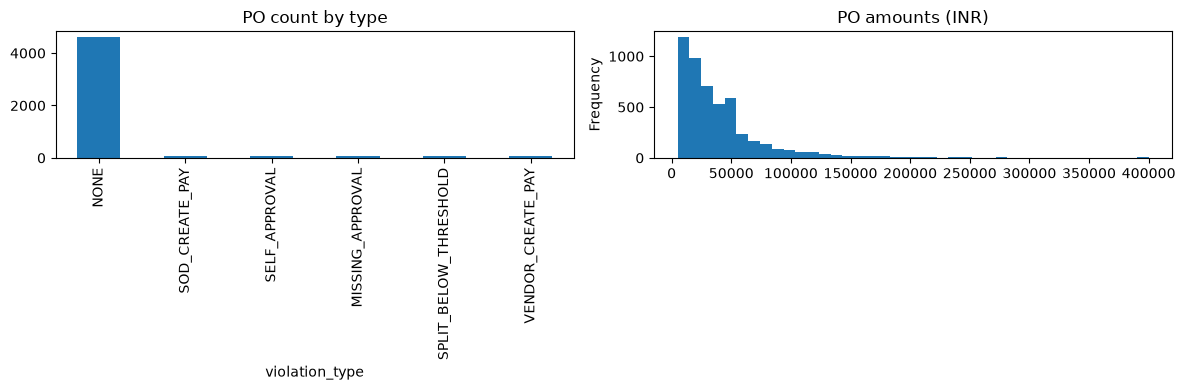

In [7]:
import matplotlib.pyplot as plt
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
labels_df["violation_type"].value_counts().plot.bar(ax=ax[0], title="PO count by type")
events_df[events_df.event_type == "PO_CREATED"]["amount"].plot.hist(ax=ax[1], bins=40, title="PO amounts (INR)")
plt.tight_layout(); plt.savefig("../results/phase2_data_overview.png", dpi=150)

text summary

In [8]:
STEP_NAME = {"PO_CREATED": "Created", "PO_APPROVED": "Approved", "GOODS_RECEIVED": "Goods received",
             "INVOICE_POSTED": "Invoice posted", "PAYMENT_POSTED": "Payment posted"}

# Context feature: how many OTHER POs did the same creator raise to the same vendor within 7 days?
created = events_df[events_df.event_type == "PO_CREATED"][
    ["po_number", "user_id", "vendor_id", "timestamp"]].rename(
    columns={"user_id": "creator", "timestamp": "created_ts"})

def near_count(row):
    m = created[(created.creator == row.creator) & (created.vendor_id == row.vendor_id) &
                (created.po_number != row.po_number) &
                ((created.created_ts - row.created_ts).abs() <= pd.Timedelta(days=7))]
    return len(m)

created["same_vendor_7d"] = created.apply(near_count, axis=1)
CTX = created.set_index("po_number")["same_vendor_7d"].to_dict()

def summarise(po, g):
    g = g.sort_values("timestamp")
    vendor, amount = g.iloc[0]["vendor_id"], g.iloc[0]["amount"]
    lines = [f"PO {po} | vendor {vendor} | amount INR {amount:,}"]
    for i, (_, r) in enumerate(g.iterrows(), 1):
        lines.append(f"{i}. {STEP_NAME[r.event_type]} by {r.user_id} "
                     f"(roles: {ROLES_OF[r.user_id]}) on {r.timestamp:%Y-%m-%d %H:%M}")
    near = "yes" if APPROVAL_LIMIT * 0.9 <= amount < APPROVAL_LIMIT else "no"
    lines.append(f"Context: vendor {vendor} was created by {VENDOR_CREATOR[vendor]}. "
                 f"Other POs by the same creator to this vendor within 7 days: {CTX[po]}. "
                 f"Amount within 10% below the INR {APPROVAL_LIMIT:,} limit: {near}.")
    return "\n".join(lines)

summ = {po: summarise(po, g) for po, g in events_df.groupby("po_number")}
po_df = labels_df.copy()
po_df["summary"] = po_df["po_number"].map(summ)
print(po_df.loc[po_df.violation_type == "SOD_CREATE_PAY", "summary"].iloc[0])

PO PO-14601 | vendor V037 | amount INR 32,880
1. Created by U047 (roles: PO_CREATOR|PAYMENT_PROCESSOR) on 2026-05-25 16:23
2. Approved by U017 (roles: PO_APPROVER) on 2026-05-26 04:23
3. Goods received by U023 (roles: WAREHOUSE) on 2026-06-03 04:23
4. Invoice posted by U032 (roles: AP_CLERK) on 2026-06-04 04:23
5. Payment posted by U047 (roles: PO_CREATOR|PAYMENT_PROCESSOR) on 2026-06-06 04:23
Context: vendor V037 was created by U041. Other POs by the same creator to this vendor within 7 days: 0. Amount within 10% below the INR 50,000 limit: no.


split into train, dev and test

In [9]:
po_df["group"] = po_df["cluster_id"].fillna(po_df["po_number"])  # keep each split-cluster together
assign = {}
for vt, g in po_df.groupby("violation_type"):
    groups = g["group"].unique().tolist(); random.shuffle(groups)
    kt, kd = max(1, int(len(groups) * 0.20)), max(1, int(len(groups) * 0.10))
    for x in groups[:kt]:        assign[x] = "test"
    for x in groups[kt:kt+kd]:   assign[x] = "dev"
po_df["split"] = po_df["group"].map(assign).fillna("train")

print(pd.crosstab(po_df["violation_type"], po_df["split"]))

po_df.drop(columns="group").to_csv("../data/po_summaries.csv", index=False)
for s in ["train", "dev", "test"]:
    po_df[po_df.split == s].drop(columns="group").to_csv(f"../data/po_{s}.csv", index=False)

split                  dev  test  train
violation_type                         
MISSING_APPROVAL         9    18     63
NONE                   460   920   3220
SELF_APPROVAL            9    18     63
SOD_CREATE_PAY           9    18     63
SPLIT_BELOW_THRESHOLD    4     8     59
VENDOR_CREATE_PAY        7    14     49
